# 03 · Signatures — embryonic module geography (Gate 2)

Show the three embryonic module signatures (**raw `score_genes`**, reference style) on the house linear layout with external colorbars, and read the module geography off the scores. **Gate 2** asks whether a Gast/pSom co-expression hub diverges into two arms (branching) or the programs form overlapping/inverse gradients (non-branching).

In [ ]:
import os, sys, glob, warnings, contextlib, io
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
import scipy.sparse as sp
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components
import logging
for lg in ['harmonypy']:
    logging.getLogger(lg).setLevel(logging.ERROR); logging.getLogger(lg).disabled=True
sc.settings.verbosity = 0
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
pth_cb  = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)
CITE='Zhang et al., 2021'
adata = sc.read_h5ad(os.path.join(pth_out,'manifold.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
print('loaded manifold.h5ad', adata.shape)

loaded manifold.h5ad (11136, 23065)


### Module geography — is there a Gast/pSom co-expression hub?
A branching pattern needs a **hub** where Gast and pSom are jointly high (the convergence zone that diverges into arms). I test whether Gast-high and pSom-high cells co-occur more than expected by chance, and whether any region is Gast-high while another is pSom-high (two arms).

In [ ]:
o = adata.obs
gq = o.Gast_sm > o.Gast_sm.quantile(.66)
pq = o.pSom_sm > o.pSom_sm.quantile(.66)
cq = o.Crest_sm > o.Crest_sm.quantile(.66)
print('Gast&pSom co-high: %d (%.1f%%) vs %.1f%% expected if independent -> %s'%(
    (gq&pq).sum(), 100*(gq&pq).mean(), 100*gq.mean()*pq.mean(),
    'DEPLETED (no hub)' if (gq&pq).mean() < gq.mean()*pq.mean() else 'enriched (hub)'))
print('pSom&Crest co-high: %d (%.1f%%)  |  Gast&Crest co-high: %d (%.1f%%)'%(
    (pq&cq).sum(),100*(pq&cq).mean(), (gq&cq).sum(),100*(gq&cq).mean()))
print('\nmodule spatial correlations (smoothed): Gast-pSom %.3f  pSom-Crest %.3f  Gast-Crest %.3f'%(
    np.corrcoef(o.Gast_sm,o.pSom_sm)[0,1], np.corrcoef(o.pSom_sm,o.Crest_sm)[0,1], np.corrcoef(o.Gast_sm,o.Crest_sm)[0,1]))
print('Gast-high cells: mean pSom_sm=%.3f (global %.3f)  |  pSom-high cells: mean Gast_sm=%.3f (global %.3f)'%(
    o.loc[gq,'pSom_sm'].mean(), o.pSom_sm.mean(), o.loc[pq,'Gast_sm'].mean(), o.Gast_sm.mean()))
print('=> no Gast/pSom co-expression hub, no Gast-high arm; pSom<->Crest is the dominant inverse axis.')

Gast&pSom co-high: 551 (4.9%) vs 11.6% expected if independent -> DEPLETED (no hub)
pSom&Crest co-high: 164 (1.5%)  |  Gast&Crest co-high: 1743 (15.7%)

module spatial correlations (smoothed): Gast-pSom -0.527  pSom-Crest -0.797  Gast-Crest 0.176
Gast-high cells: mean pSom_sm=0.068 (global 0.082)  |  pSom-high cells: mean Gast_sm=-0.045 (global -0.033)
=> no Gast/pSom co-expression hub, no Gast-high arm; pSom<->Crest is the dominant inverse axis.


### Branch test on the tree — do any node-clusters resolve Gast-high vs pSom-high arms?
If branching were real, distinct tree segments would separate into Gast-high and pSom-high arms. Here every segment has near-identical module means (the forks are geometric over-fitting).

In [ ]:
a = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(a, method='ppt', Nodes=150, ppt_lambda=2000, ppt_sigma=.5, use_rep='X_umap_lin' if False else 'X_umap', seed=SEED, plot=False)
    R = np.asarray(a.obsm['X_R']); nP=(R.T@a.obs.pSom.values)/R.sum(0)
    scf.tl.root(a, int(np.argmax(nP))); scf.tl.pseudotime(a, n_map=1, seed=SEED)
seg = a.obs.groupby(a.obs.seg.astype(str), observed=True).agg(
        n=('t','size'), Gast=('Gast','mean'), pSom=('pSom','mean'), Crest=('Crest','mean'))
print('per-segment module means (n=%d segments):'%len(seg))
print(seg.round(3).to_string())
print('\nmodule SPREAD across segments: Gast %.3f  pSom %.3f  Crest %.3f  (tiny -> no arms)'%(
    seg.Gast.max()-seg.Gast.min(), seg.pSom.max()-seg.pSom.min(), seg.Crest.max()-seg.Crest.min()))

per-segment module means (n=13 segments):
        n   Gast   pSom  Crest
seg                           
1    1706 -0.031  0.080 -0.054
10    631 -0.028  0.083 -0.063
11   1258 -0.040  0.090 -0.066
12   1924 -0.039  0.078 -0.052
13    249 -0.040  0.096 -0.063
2     479 -0.037  0.083 -0.051
3     401 -0.040  0.097 -0.066
4     290 -0.041  0.096 -0.066
5     204 -0.042  0.086 -0.055
6    1714 -0.022  0.082 -0.058
7     254 -0.034  0.096 -0.073
8     687 -0.028  0.081 -0.064
9    1339 -0.039  0.093 -0.069

module SPREAD across segments: Gast 0.020  pSom 0.019  Crest 0.022  (tiny -> no arms)


**Gate 2 = GO (non-branching).** No Gast/pSom co-expression hub (co-high depleted), no Gast-high arm — all tree segments are module-identical. The pattern is the **non-branching cross-repression sub-case** (Wu2021-ratified): an organized pSom(origin)↔Crest(terminal) inverse gradient with Gast/pSom cross-repression. Crest is terminal and opposes the pSom origin — it does **not** enrich a Gast arm → **no flag**. No bifurcation → **Gate 3 NA**.

### Signature UMAPs — RAW scores, house layout, external colorbars
Deliverable signature panels show **raw** `score_genes` values (smoothing aids the geography read above but the deliverable must show raw, per the binding spec).

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


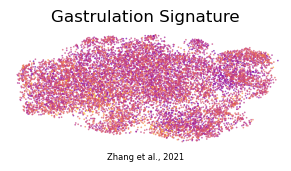

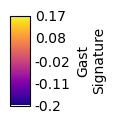

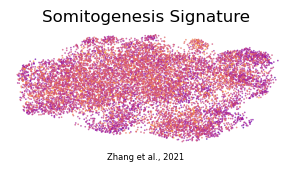

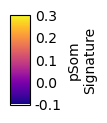

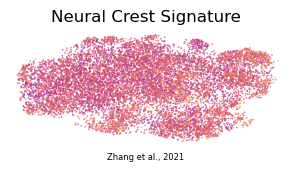

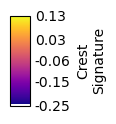

In [ ]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(adata, color=m, cmap='plasma', alpha=.7, size=6, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12, CITE, ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight'); plt.show()
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight'); plt.show()
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [ ]:
adata.write(os.path.join(pth_out,'signatures.h5ad'))
print('saved signatures.h5ad | Gate 2 = GO (non-branching); Gate 3 = NA')

saved signatures.h5ad | Gate 2 = GO (non-branching); Gate 3 = NA
